# ED arrivals forecast model
Predicts how many patients arrive at the Emergency Department in the next hour.

- Data: `data/datasets/ed_model_data.csv`
- Target: `arrivals`
- Models: baseline, XGBoost, Random Forest

In [1]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

## 1. Load data

In [2]:
df = pd.read_csv('../data/datasets/ed_model_data.csv')
print(df.shape)
df.head()

(24168, 16)


,timestamp,hour,day_of_week,month,is_weekend,is_holiday,lag_1,lag_24,lag_168,roll_mean_6,roll_mean_24,occupancy_rate_lag1,avg_wait_min_lag1,staff_availability_pct_lag1,arrivals,split
0,2024-01-08 00:00:00,0,0,1,0,0,32.0,11.0,16.0,31.17,24.92,0.45,86.1,66.7,17,train
1,2024-01-08 01:00:00,1,0,1,0,0,17.0,15.0,16.0,27.33,25.17,0.25,19.8,66.7,11,train
2,2024-01-08 02:00:00,2,0,1,0,0,11.0,15.0,19.0,24.83,25.00,0.25,17.9,66.7,13,train
3,2024-01-08 03:00:00,3,0,1,0,0,13.0,20.0,7.0,21.50,24.92,0.30,16.7,66.7,6,train
4,2024-01-08 04:00:00,4,0,1,0,0,6.0,8.0,17.0,17.33,24.33,0.10,13.2,66.7,16,train


## 2. Features and target
`timestamp` and `split` are not used as features.

In [3]:
x = df.drop(columns=['arrivals', 'timestamp', 'split'])
y = df['arrivals']

## 3. Train and test split
Split by time (no shuffle): older rows for training, newest 20% for testing.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, shuffle=False)

## 4. Baseline
Simple guess: arrivals will be the same as the same hour last week (`lag_168`). The models must beat this.

In [5]:
base_pred = x_test['lag_168']

## 5. XGBoost

In [6]:
xgb = XGBRegressor(n_estimators=50, random_state=42)
xgb.fit(x_train, y_train)
xgb_pred = xgb.predict(x_test)

## 6. Random Forest

In [7]:
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_test)

## 7. Comparison
MAE = average error in patients per hour. RMSE punishes big misses more.

In [8]:
def report(name, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    print(f'{name:<14} MAE: {mae:.2f}   RMSE: {rmse:.2f}')

report('Baseline', base_pred)
report('XGBoost', xgb_pred)
report('Random Forest', rf_pred)

Baseline       MAE: 11.59   RMSE: 15.78
XGBoost        MAE: 8.34   RMSE: 11.45
Random Forest  MAE: 8.41   RMSE: 11.46


Results from the last run: Baseline MAE 11.59, XGBoost MAE 8.34 (RMSE 11.45), Random Forest MAE 8.41 (RMSE 11.46). Both models beat the baseline.

## 8. Actual vs predicted (first week of the test set)

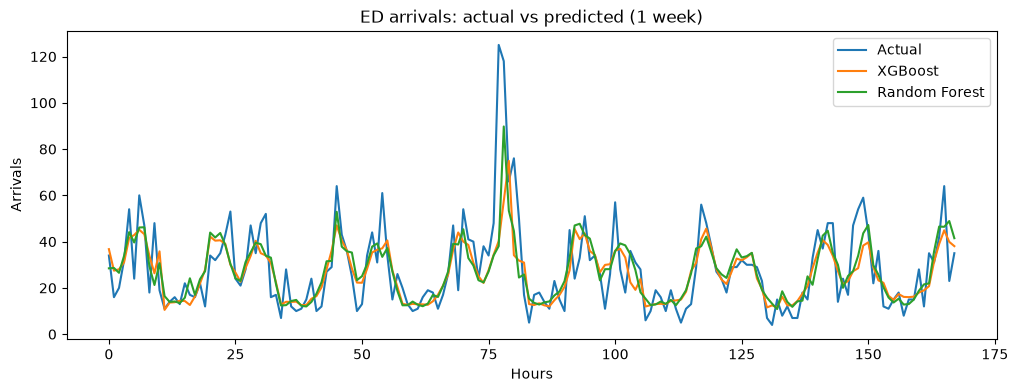

In [9]:
plt.figure(figsize=(12, 4))
plt.plot(y_test.values[:168], label='Actual')
plt.plot(xgb_pred[:168], label='XGBoost')
plt.plot(rf_pred[:168], label='Random Forest')
plt.xlabel('Hours')
plt.ylabel('Arrivals')
plt.title('ED arrivals: actual vs predicted (1 week)')
plt.legend()
plt.show()

## 9. Feature importance (XGBoost)

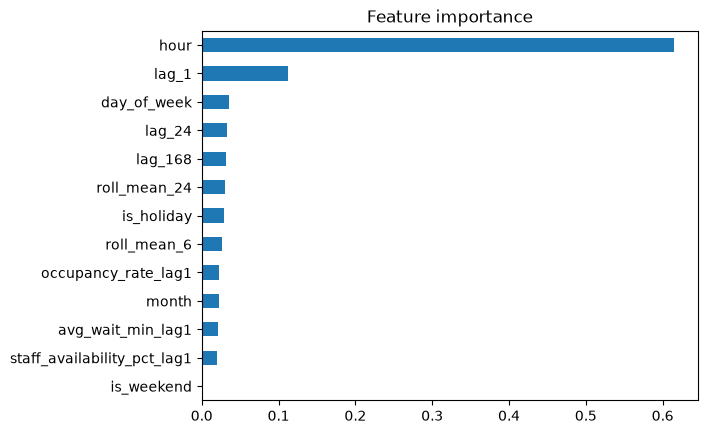

In [10]:
pd.Series(xgb.feature_importances_, index=x.columns).sort_values().plot(kind='barh', title='Feature importance')
plt.show()

## 10. Save the better model
The model and its feature list are saved in `ML/saved_models/` and used by `ml_tools.py`.

In [11]:
best = xgb if mean_absolute_error(y_test, xgb_pred) <= mean_absolute_error(y_test, rf_pred) else rf

os.makedirs('saved_models', exist_ok=True)
joblib.dump(best, 'saved_models/arrivals_model.joblib')
joblib.dump(list(x.columns), 'saved_models/arrivals_features.joblib')
print('Saved:', type(best).__name__)

Saved: XGBRegressor
